# Goal of the notebook:
## Here we extract the inward coordinates of the three first exploratory flights of Bee 1, before her first exploitation flight.
## Some additional statistics for each flight are provided, to have a better understanding of Woodgate 2016 data.

# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gps_bumblebee_rothamsted as gbr
import utils

# Charge excel into Dataframe

In [3]:
radar_tracks_path = 'Woodgate&Chittka2016/original_radar_tracks.xlsx'
radar_tracks_df = utils.read_excel_to_dataframe(radar_tracks_path)

if radar_tracks_df is not None:
    print(radar_tracks_df.columns)
    print(radar_tracks_df.head())

Index(['Bee', 'FlightNo', 'Date', 'Time', 'X', 'Y', 'Latitude', 'Longitude',
       'Radar-Latitude', 'Radar-Longitude', 'Nest-Latitude', 'Nest-Longitude'],
      dtype='object')
   Bee  FlightNo       Date      Time         X         Y   Latitude  \
0    1         1 2015-06-25  10:17:40  0.801607 -1.639710  51.803806   
1    1         1 2015-06-25  10:17:43  1.017720 -1.431892  51.803808   
2    1         1 2015-06-25  10:17:46  1.017720 -1.431892  51.803808   
3    1         1 2015-06-25  10:17:49  1.017720 -1.431892  51.803808   
4    1         1 2015-06-25  10:17:51  1.017720 -1.431892  51.803808   

   Longitude  Radar-Latitude  Radar-Longitude  Nest-Latitude  Nest-Longitude  
0  -0.368911       51.803721         -0.36706      51.803821       -0.368923  
1  -0.368908       51.803721         -0.36706      51.803821       -0.368923  
2  -0.368908       51.803721         -0.36706      51.803821       -0.368923  
3  -0.368908       51.803721         -0.36706      51.803821       -0.36

# Preprocess dataframe to our need

In [4]:
df = gbr.rename_columns(radar_tracks_df)
print(df.columns)
df = gbr.add_first_flight_date(df)
df = gbr.convert_lat_long_to_osgb36(df)
df = gbr.add_distance_to_nest_column(df)
df = gbr.add_time_between_steps_column(df)
df = gbr.add_flight_times_columns(df)
df = gbr.add_distance_between_steps_column(df)
df = gbr.add_speed_between_steps_column(df)
df = gbr.classify_inward_outward_trajectories(df)
df = gbr.sum_and_max(df)
df = gbr.add_stops(df)
df = gbr.compute_disgressiveness(df)
df = gbr.classify_flight_type(df)

df_pruned = gbr.drop_columns(df)

Index(['Bee_ID', 'BeeFlightNo', 'Date', 'Time (hh:mm:ss)', 'X', 'Y',
       'Bee_Latitude_WGS84', 'Bee_Longitude_WGS84', 'Radar_Latitude_WGS84',
       'Radar_Longitude_WGS84', 'Nest_Latitude_WGS84', 'Nest_Longitude_WGS84'],
      dtype='object')


In [5]:
df_pruned.columns

Index(['Bee_ID', 'BeeFlightNo', 'Date', 'Time (hh:mm:ss)', 'First_Flight_Date',
       'Bee_Latitude_OSGB36', 'Bee_Longitude_OSGB36', 'Radar_Latitude_OSGB36',
       'Radar_Longitude_OSGB36', 'Nest_Latitude_OSGB36',
       'Nest_Longitude_OSGB36', 'Distance_to_nest (m)',
       'Time_between_steps (s)', 'Total_Flight_Time', 'Total_Pause_Time',
       'Total_Active_Time', 'Ratio_Active_Total', 'Distance_between_steps (m)',
       'Speed_between_steps (m/s)', 'Direction', 'Observed_FlightDistance',
       'Max_Distance_to_Nest', 'Distance_Nest_to_First',
       'Distance_Last_to_Nest', 'Fulltrip_FlightDistance', 'Mean_Flight_Speed',
       'Last_Flight', 'Total_Stops', 'Disgressiveness', 'Flight_Type'],
      dtype='object')

# Table from the original Paper, Summarising the average flight characteristics of each bee
## Life-Long Radar Tracking of Bumblebees (Woodgate, Chittka, 2016)

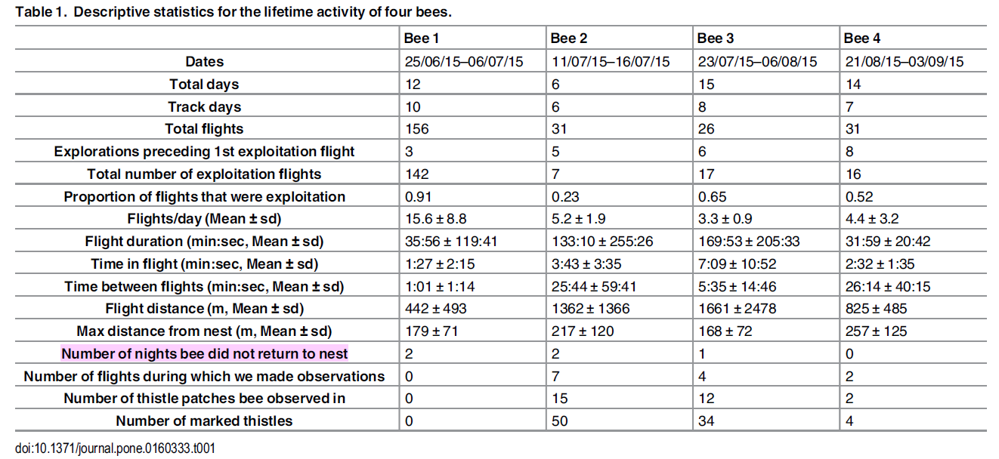

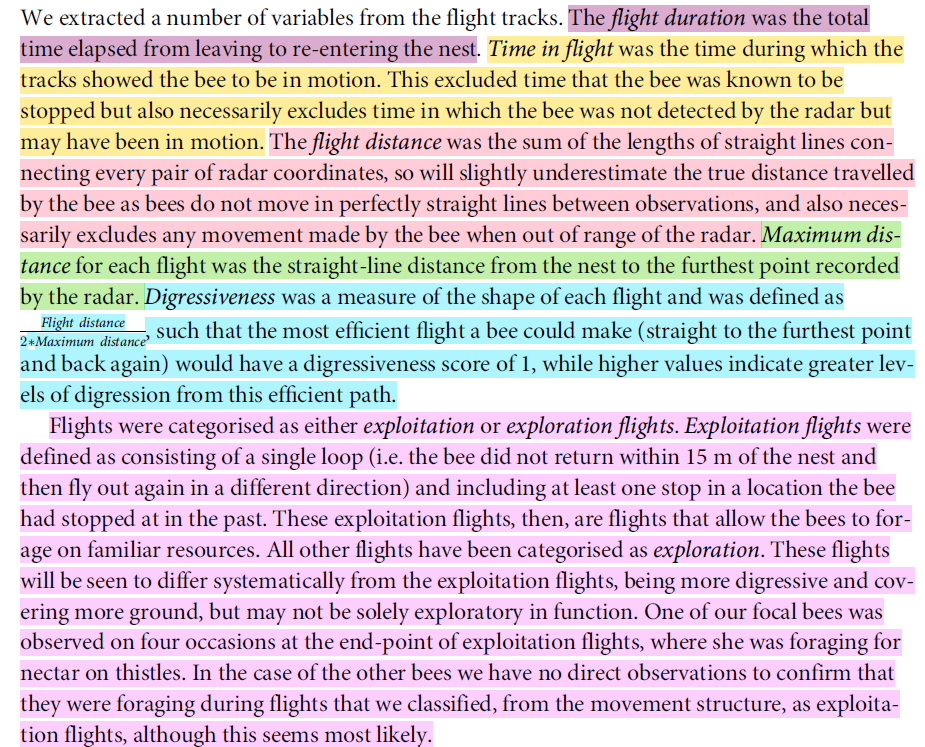

Why not use disgressiveness and stops to categorize exploration flights:  Flight where bees did not land are 

# Visualize and summarize each single flight

### Stops are defined as intervals of more than 180 seconds between timesteps (could happen because of non-detection of the bee behind a tree)

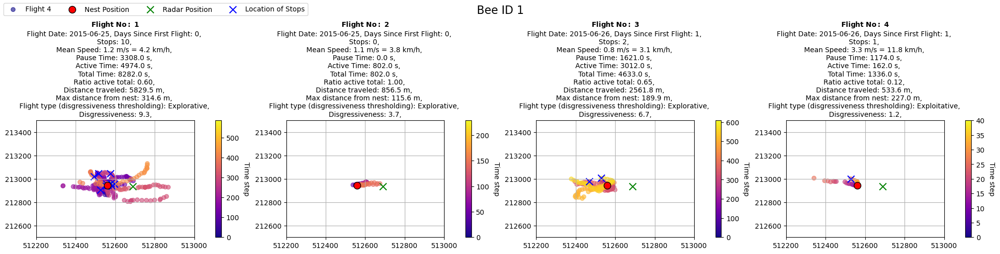

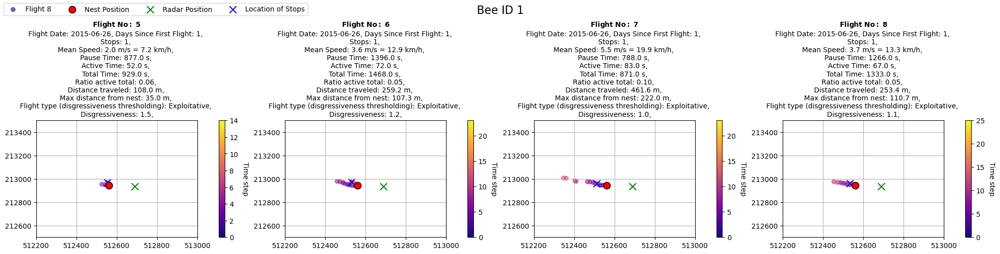

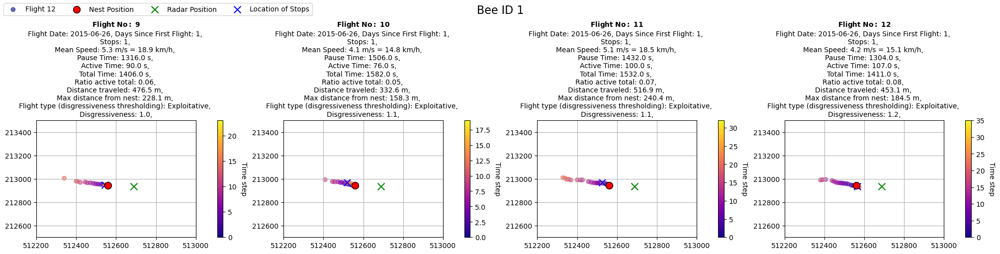

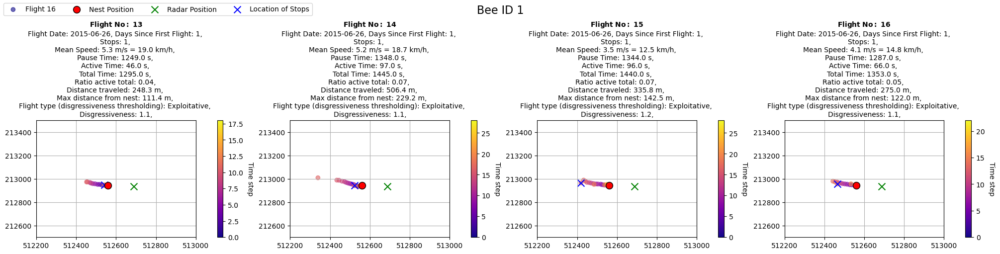

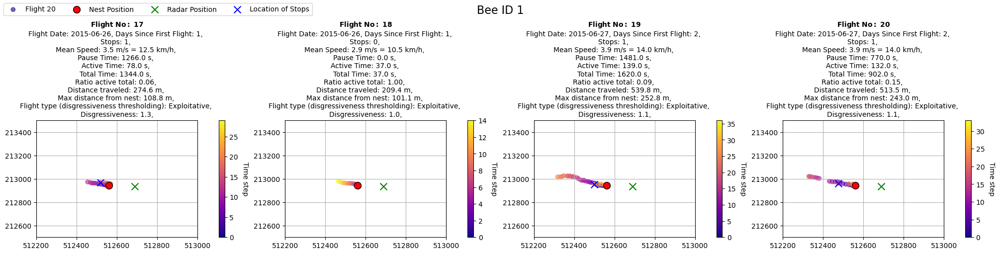

...

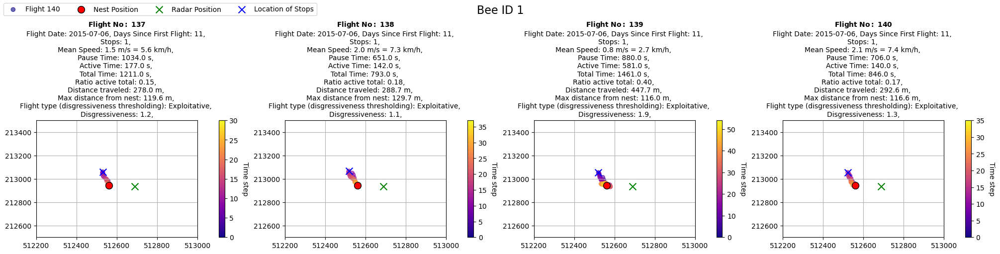

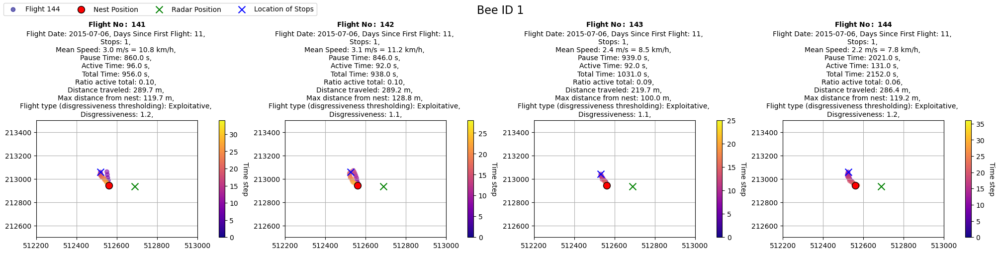

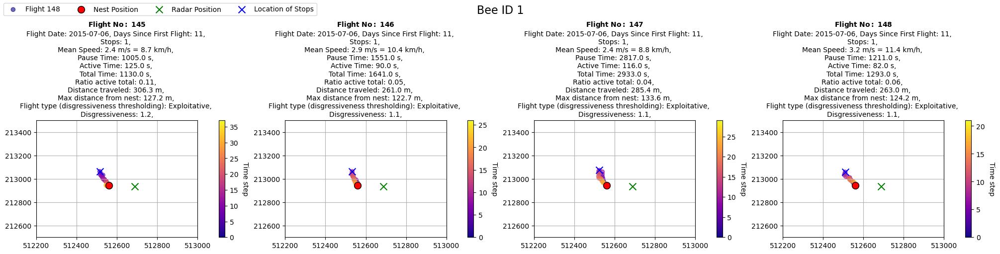

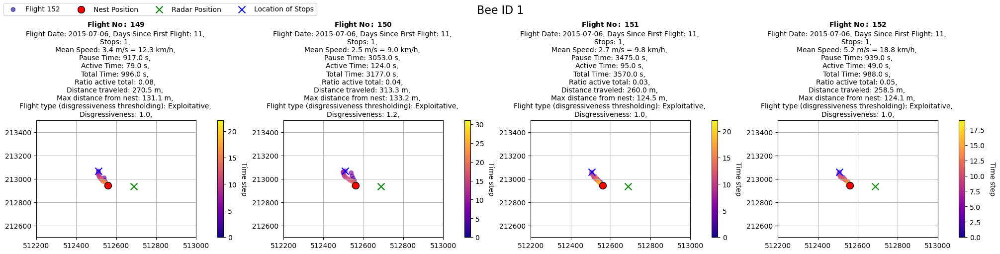

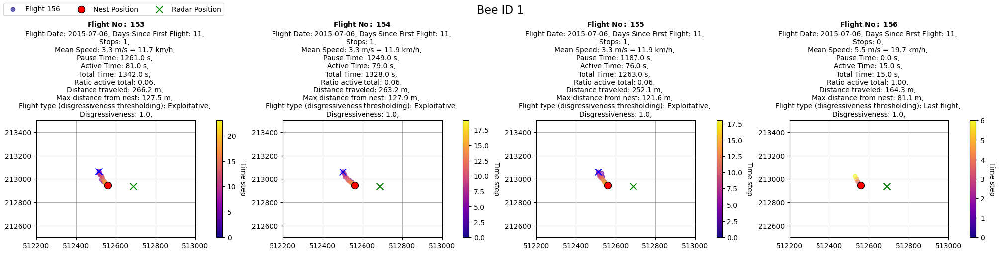

In [6]:
bee_id = 1
easting_boundaries = (512200, 513000)  # Example boundaries, adjust as necessary
northing_boundaries = (212500, 213500)  # Example boundaries, adjust as necessary
gbr.plot_individual_flights(df_pruned, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



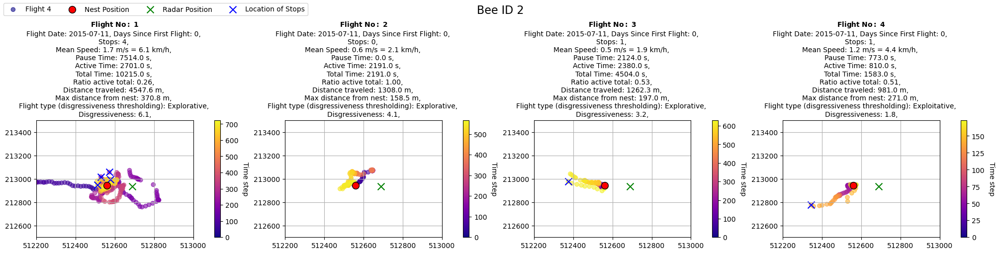

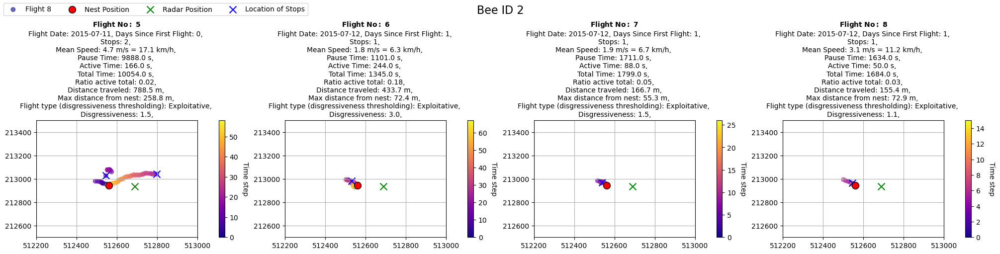

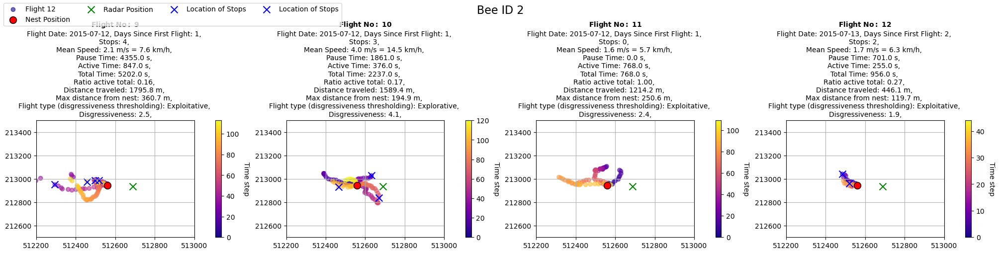

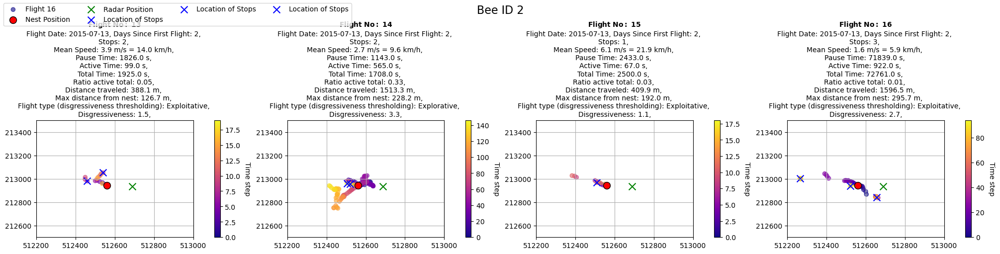

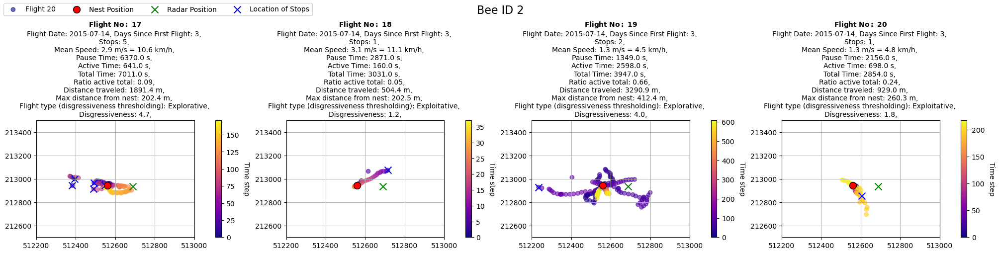

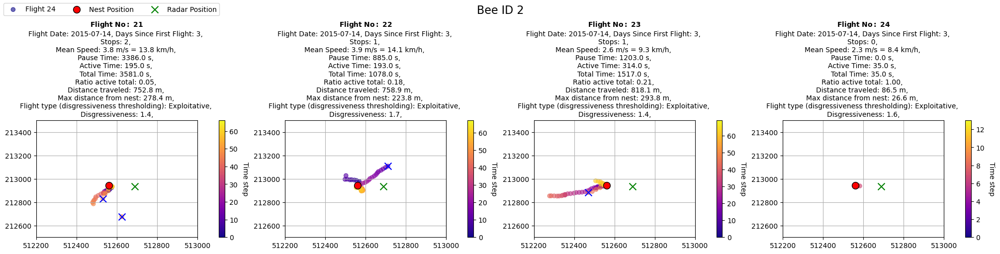

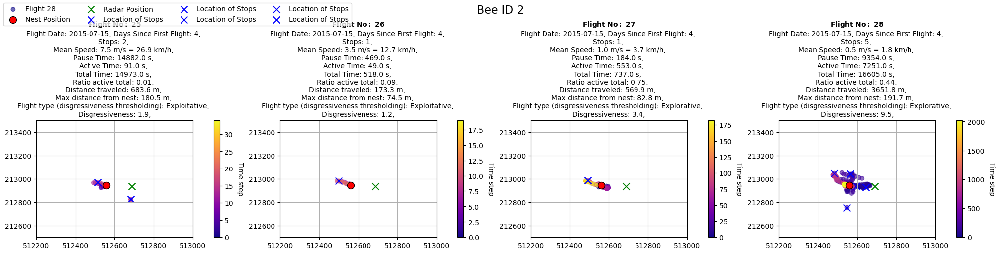

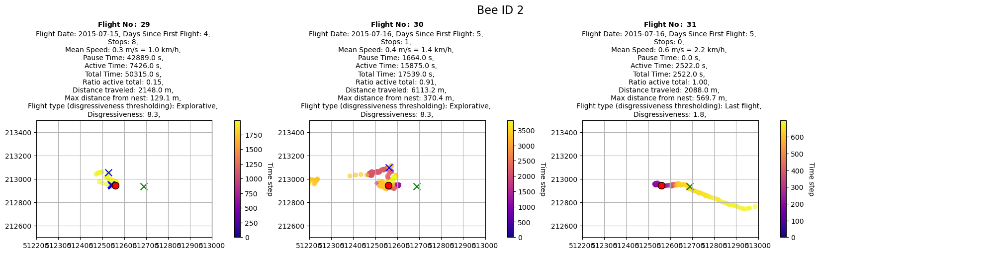

In [7]:
bee_id = 2
gbr.plot_individual_flights(df_pruned, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)

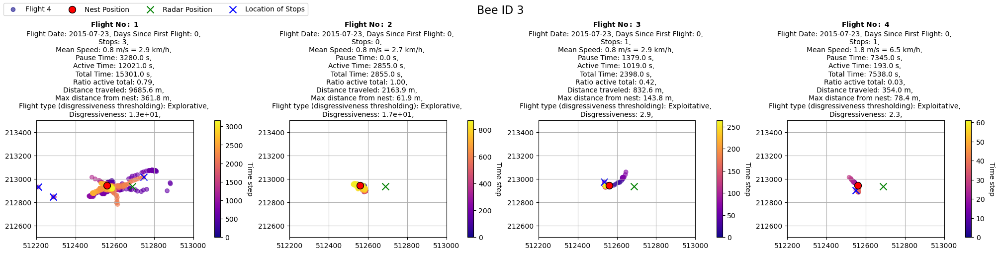

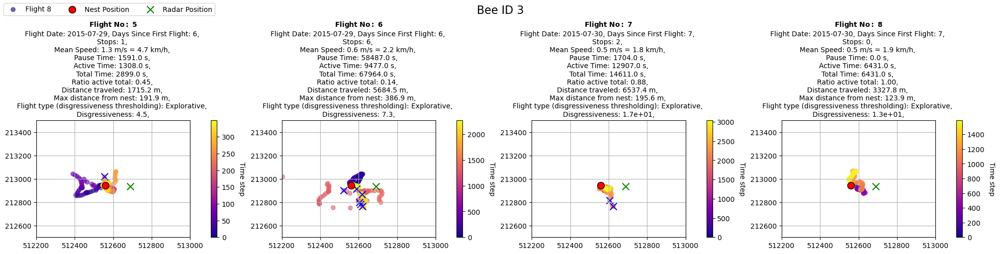

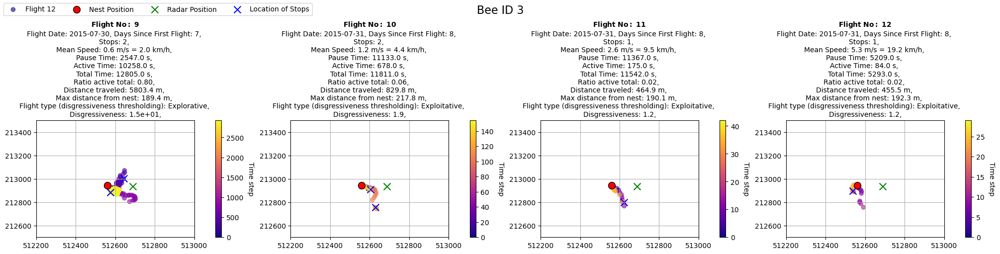

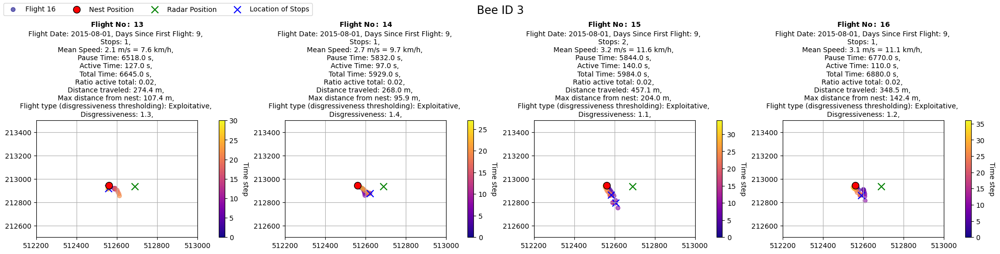

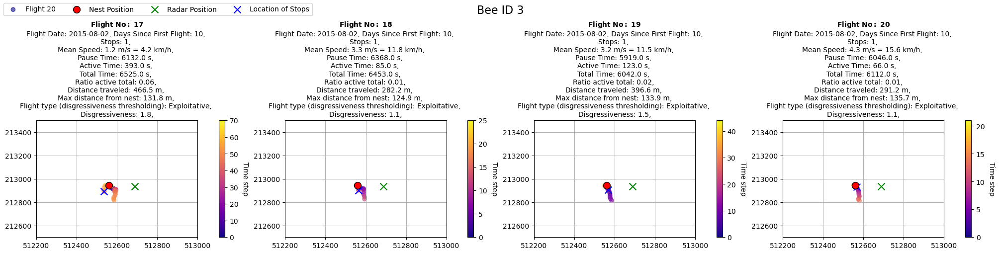

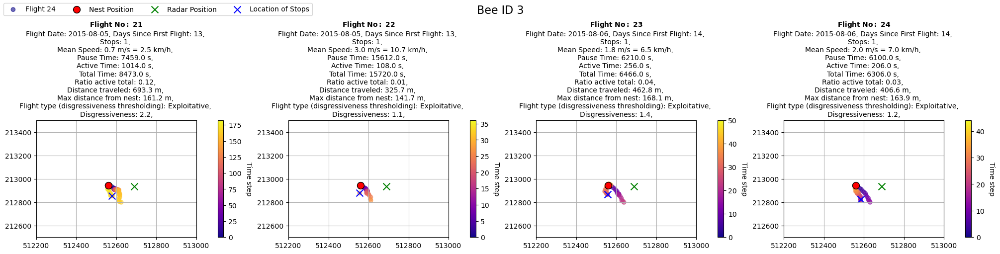

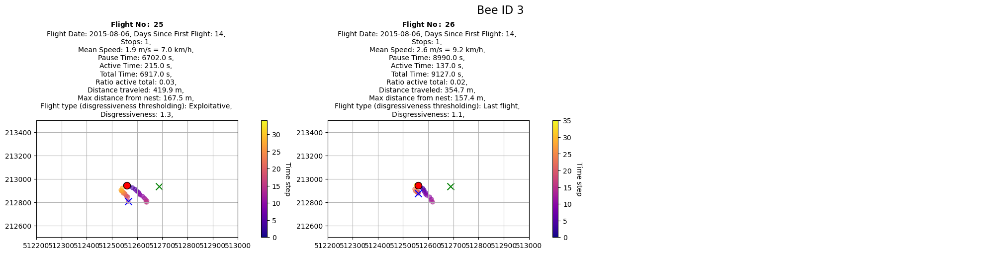

In [8]:
bee_id = 3
gbr.plot_individual_flights(df_pruned, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



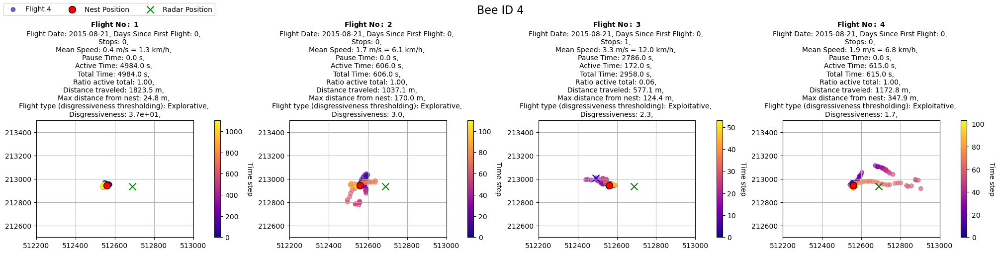

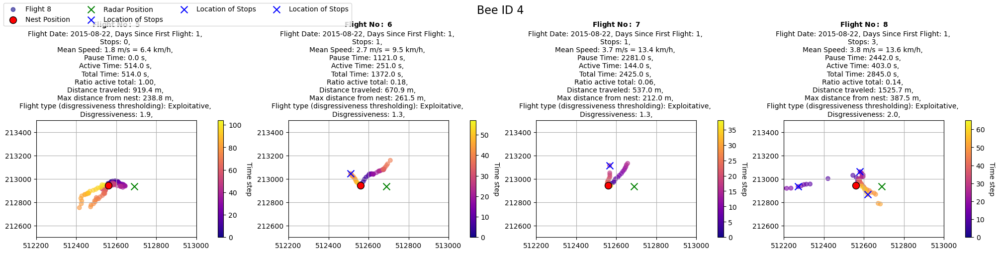

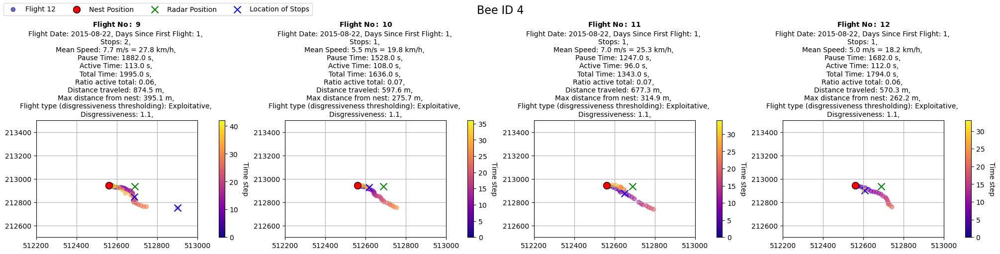

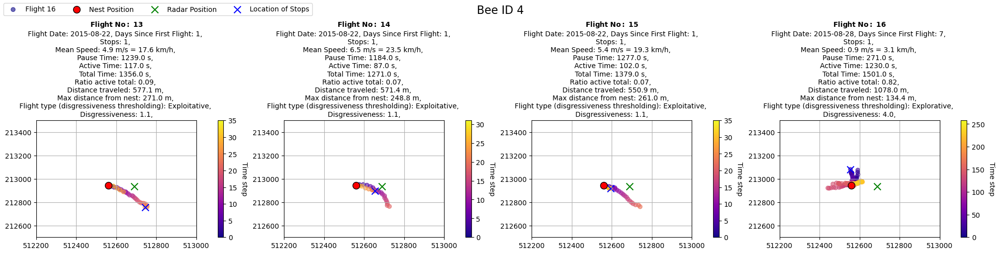

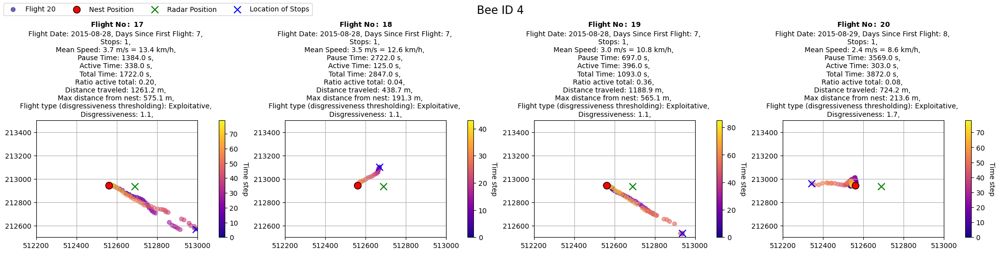

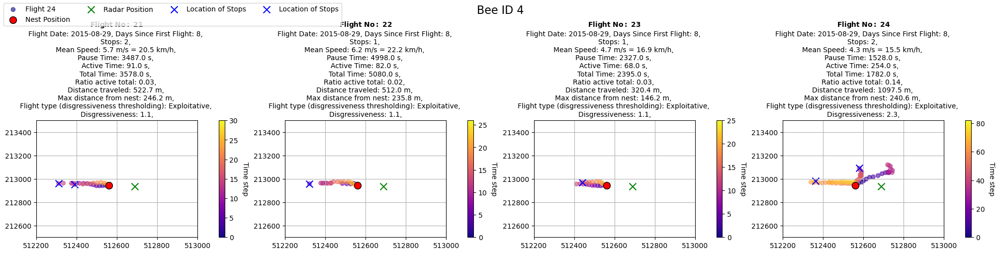

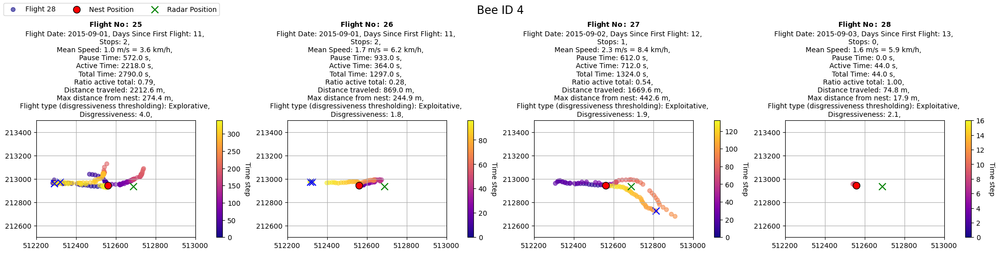

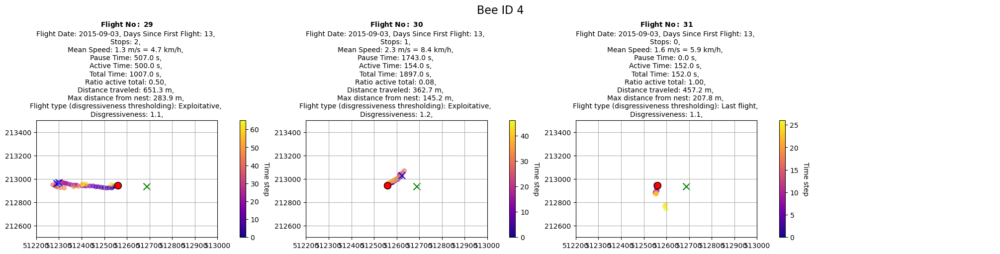

In [9]:
bee_id = 4
gbr.plot_individual_flights(df_pruned, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



# Extracting the three first flights of Bee 1 as the exploration flights, everything other flight of bee 1 will be saved as exploitation data. The last flight is discarded.
## According to Woodgate et al (2016) the three first flights of Bee 1 are exploration flights. And the fourth flight is the first exploitation flight

In [10]:
# must be inward and explorative
df_exploration_bee1, df_exploitation_bee1  = gbr.get_flight_data(df_pruned, 1, [1,2,3])
df_exploration_bee1 = df_exploration_bee1[df_exploration_bee1["Direction"]=="Inward"]

# # must be anything else, not the last flight though
df_exploitation_bee1 =  df_exploitation_bee1[df_exploitation_bee1["Flight_Type"] != "Last flight"]

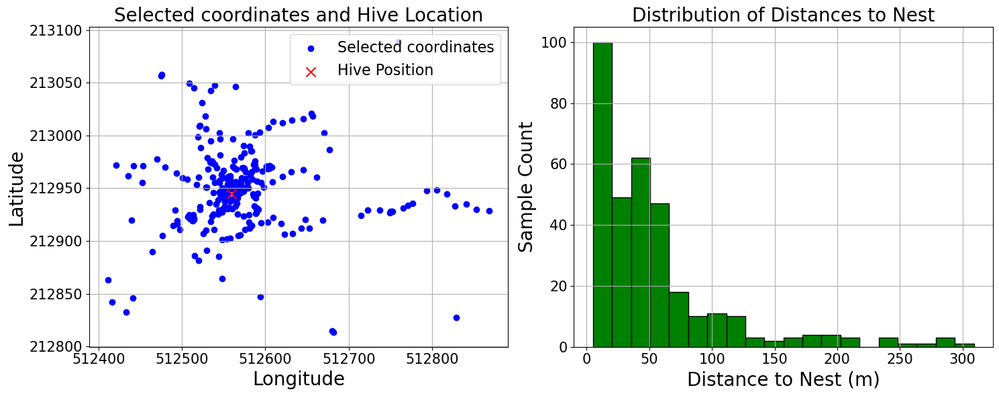

Coordinates and hive position saved to exploration_inward_XY_Bee1.csv
(335, 4)


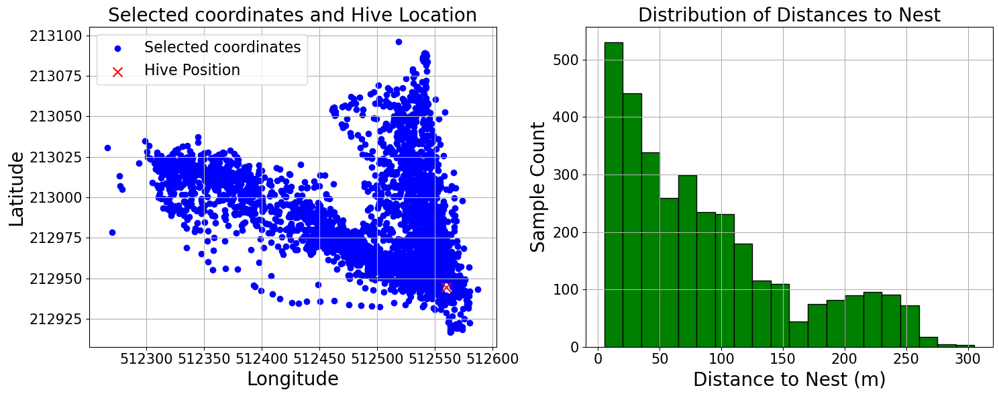

Coordinates and hive position saved to exploitation_XY_Bee1.csv
(3309, 4)


In [11]:
coords = gbr.extract_coordinates(df_exploration_bee1, display=True, save_to="exploration_inward_coords_Bee1.csv", removal_distance=5)
print(coords.shape)

coords = gbr.extract_coordinates(df_exploitation_bee1, display=True, save_to="exploitation_coords_Bee1.csv", removal_distance=5)
print(coords.shape)

# Categorization of flights (exploratory or exploitative) based on Woodgate definition:
### Not finished yet 

# Categorization of flight based on a disgressiveness threshold.
## Every flight with a too high disgressiveness is classified as exploratory. 
### We argue this is a better way of classifying exploratory flights than the Woodgate method, which often select seemingly exploitative path as explorative

In [12]:
df_exploration = df_pruned[df_pruned["Flight_Type"] == "Explorative"]
df_exploitation =  df_pruned[df_pruned["Flight_Type"] == "Exploitative"]

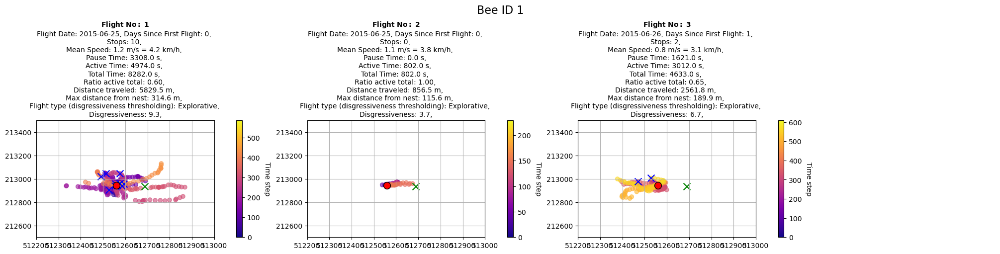

In [13]:
bee_id = 1
gbr.plot_individual_flights(df_exploration, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



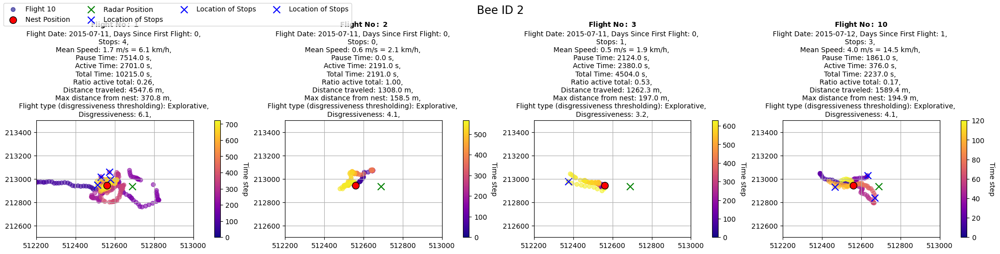

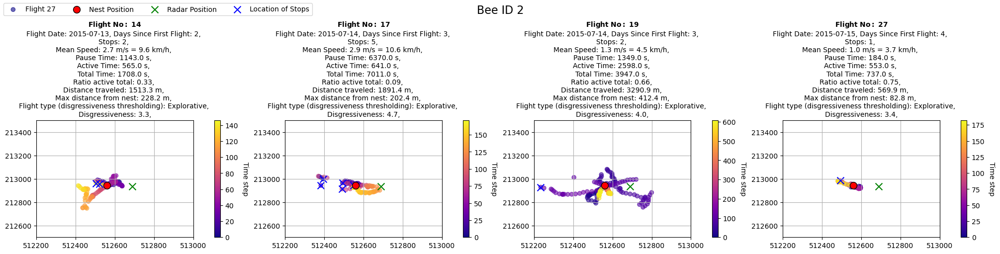

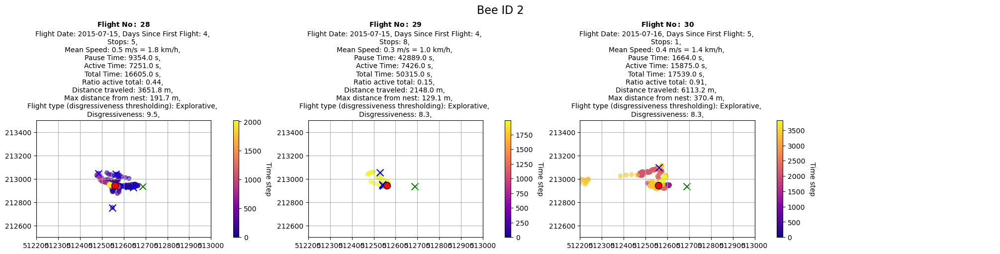

In [14]:
bee_id = 2
gbr.plot_individual_flights(df_exploration, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



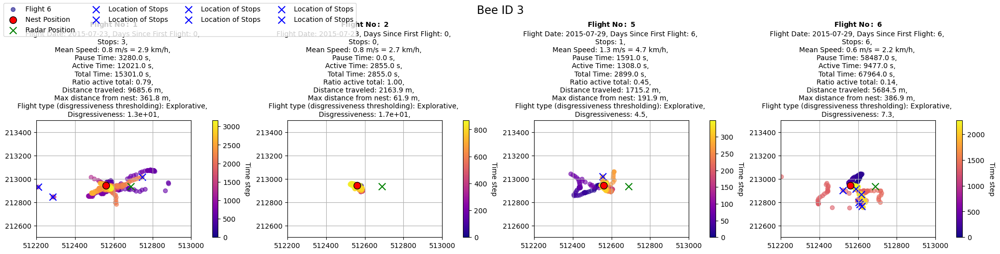

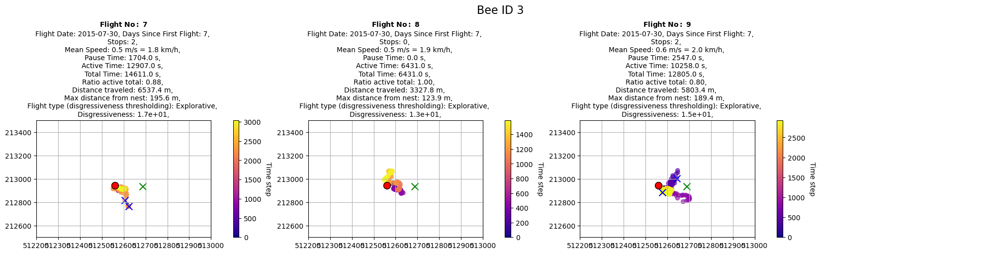

In [15]:
bee_id = 3
gbr.plot_individual_flights(df_exploration, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)



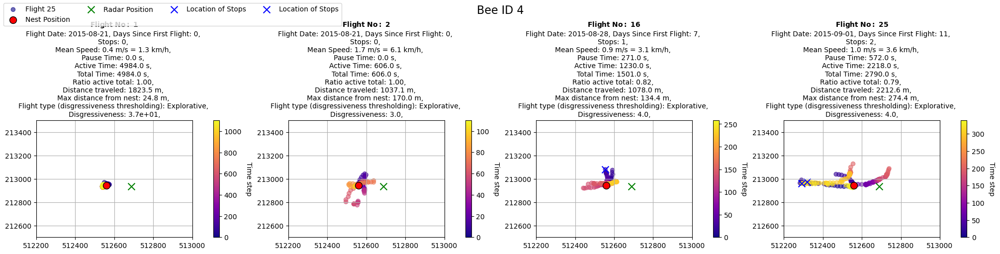

In [16]:
bee_id = 4
gbr.plot_individual_flights(df_exploration, bee_id=bee_id, rows=1, cols=4, easting_boundaries=easting_boundaries, northing_boundaries=northing_boundaries)

